<a href="https://colab.research.google.com/github/ElionesSinTalon/LSTM-Neural-Network-/blob/master/Predicci%C3%B3n_de_temperatura_con_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Cargar conjunto de datos**

In [1]:
!wget https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv -O Daily_minimum_temps.csv

--2026-10-15 07:05:02--  https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 67921 (66K) [text/plain]
Saving to: ‘Daily_minimum_temps.csv’

Daily_minimum_temps 100%[===================>]  66.33K  --.-KB/s    in 0.006s  

2026-10-15 07:05:02 (10.3 MB/s) - ‘Daily_minimum_temps.csv’ saved [67921/67921]



**Librerías y parámetros**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

tf.keras.utils.set_random_seed(42)

N_INPUT = 14      # días previos usados como entrada
N_FEATURES = 1    # solo la temperatura
N_VAL = 800       # registros para validación
N_DIAS = 15       # días a predecir a futuro

**Carga y limpieza del dataset**

In [3]:
df = pd.read_csv("Daily_minimum_temps.csv")
print(df.columns.tolist())
print(df.head())

df = df.rename(columns={df.columns[0]: "Date", df.columns[1]: "Temp"})
col = "Temp"

['Date', 'Temp']
         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8


**Inspeccionar qué registros no son números válidos**

In [4]:
raw = df[col].astype(str)
malos = df[pd.to_numeric(raw, errors="coerce").isna()]
print(f"Registros inválidos: {len(malos)}")
print(malos)

Registros inválidos: 0
Empty DataFrame
Columns: [Date, Temp]
Index: []


In [5]:
#Quitar todo lo que no sea dígito
df[col] = raw.str.replace(r"[^0-9.\-]", "", regex=True)

**Conversion a número**

In [6]:
df[col] = pd.to_numeric(df[col], errors="coerce")
print("Irrecuperables:", df[col].isna().sum())
df = df.dropna(subset=[col])

Irrecuperables: 0


**Convertir, ordenar y quitar duplicados de fechas**

In [7]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = (df.dropna(subset=["Date"])
        .sort_values("Date")
        .drop_duplicates("Date")
        .reset_index(drop=True))

**Verificar**

In [8]:
print(df[col].describe())
print(df["Date"].diff().value_counts().head())

count    3650.000000
mean       11.177753
std         4.071837
min         0.000000
25%         8.300000
50%        11.000000
75%        14.000000
max        26.300000
Name: Temp, dtype: float64
Date
1 days    3647
2 days       2
Name: count, dtype: int64


**División, normalización y ventanas de 14 días**

In [9]:
valores = df[[col]].values.astype("float32")

train_vals = valores[:-N_VAL]
val_ctx = valores[-(N_VAL + N_INPUT):]

print(f"Entrenamiento de datos: {train_vals.shape}")
print(f"Validación de datos: {valores[-N_VAL:].shape}")

Entrenamiento de datos: (2850, 1)
Validación de datos: (800, 1)


In [10]:
scaler = MinMaxScaler()
train_esc = scaler.fit_transform(train_vals)
val_esc = scaler.transform(val_ctx)
serie_esc = scaler.transform(valores)

In [11]:
def crear_ventanas(serie, n_input):
    """Convierte la serie en pares (14 días previos -> día siguiente)."""
    X, y = [], []
    for i in range(n_input, len(serie)):
        X.append(serie[i - n_input:i, 0])
        y.append(serie[i, 0])
    X = np.array(X).reshape(-1, n_input, 1)
    return X, np.array(y)

In [12]:
X_train, y_train = crear_ventanas(train_esc, N_INPUT)
X_val, y_val = crear_ventanas(val_esc, N_INPUT)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)

X_train: (2836, 14, 1) | y_train: (2836,)
X_val:   (800, 14, 1) | y_val:   (800,)


**Arquitectura de la red**

In [13]:
lstm_model = Sequential([
    Input(shape=(N_INPUT, N_FEATURES)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mse")
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

**Entrenamiento del modelo**

In [14]:
mc = ModelCheckpoint("best_model_lstm.keras", monitor="val_loss", mode="min",
                     save_best_only=True, verbose=1)
es = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = lstm_model.fit(X_train, y_train,
                         validation_data=(X_val, y_val),
                         epochs=100, batch_size=32,
                         callbacks=[mc, es])

Epoch 1/100
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0402
Epoch 1: val_loss improved from None to 0.01066, saving model to best_model_lstm.keras

Epoch 1: finished saving model to best_model_lstm.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0199 - val_loss: 0.0107
Epoch 2/100
88/89 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0123
Epoch 2: val_loss improved from 0.01066 to 0.01032, saving model to best_model_lstm.keras

Epoch 2: finished saving model to best_model_lstm.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0121 - val_loss: 0.0103
Epoch 3/100
88/89 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0122
Epoch 3: val_loss improved from 0.01032 to 0.01012, saving model to best_model_lstm.keras

Epoch 3: finished saving model to best_model_lstm.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0119 - val_loss: 0.0101
Epoch 4/100
82/89 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0122
Epoch 4: val_loss improved from 0.01012 to 0.01003, saving model to best_model

**Resultados del entrenamiento**

In [15]:
modelo = load_model("best_model_lstm.keras")

In [16]:
val_loss = modelo.evaluate(X_val, y_val, verbose=0)
rango = scaler.data_max_[0] - scaler.data_min_[0]
print(f"val_loss (MSE, datos escalados): {val_loss:.5f}")
print("Meta val_loss < 0.01:", "CUMPLIDA" if val_loss < 0.01 else "NO cumplida")
print(f"Error cuadrático medio (RMSE) aproximado: {np.sqrt(val_loss) * rango:.2f} °C")

val_loss (MSE, datos escalados): 0.00764
Meta val_loss < 0.01: CUMPLIDA
Error cuadrático medio (RMSE) aproximado: 2.30 °C


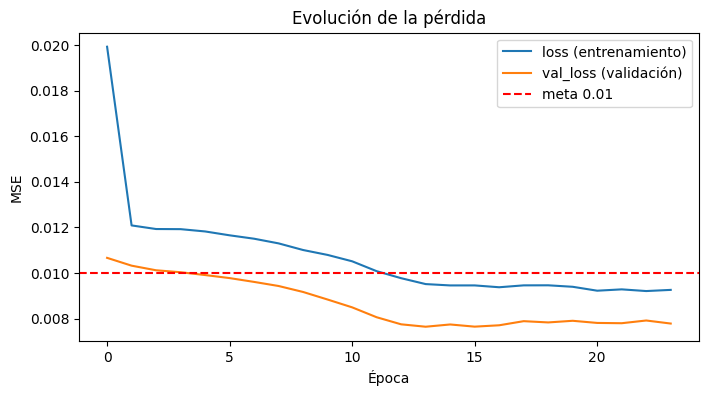

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="loss (entrenamiento)")
plt.plot(history.history["val_loss"], label="val_loss (validación)")
plt.axhline(0.01, color="red", linestyle="--", label="meta 0.01")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Evolución de la pérdida")
plt.legend()
plt.savefig("curva_loss.png", dpi=150, bbox_inches="tight")
plt.show()

**Predicción a 15 días**

In [18]:
def predecir_n_dias(modelo, ultimos, n_dias, n_input):
    """Predice un día, lo agrega a la ventana y repite n_dias veces."""
    ventana = ultimos.reshape(1, n_input, 1)
    preds = []
    for _ in range(n_dias):
        p = modelo.predict(ventana, verbose=0)[0, 0]
        preds.append(p)
        ventana = np.append(ventana[:, 1:, :], [[[p]]], axis=1)
    return np.array(preds).reshape(-1, 1)

**Comprobación si se predicen los últimos 15 días**

In [19]:
seed_bt = serie_esc[-(N_DIAS + N_INPUT):-N_DIAS]          # 14 días previos a esos 15
pred_bt = scaler.inverse_transform(predecir_n_dias(modelo, seed_bt, N_DIAS, N_INPUT))
real_bt = valores[-N_DIAS:]
fechas_bt = df["Date"].iloc[-N_DIAS:]

In [20]:
mae = np.mean(np.abs(real_bt - pred_bt))
print(f"Error absoluto medio a 15 días (comprobación): {mae:.2f} °C")

Error absoluto medio a 15 días (comprobación): 1.23 °C


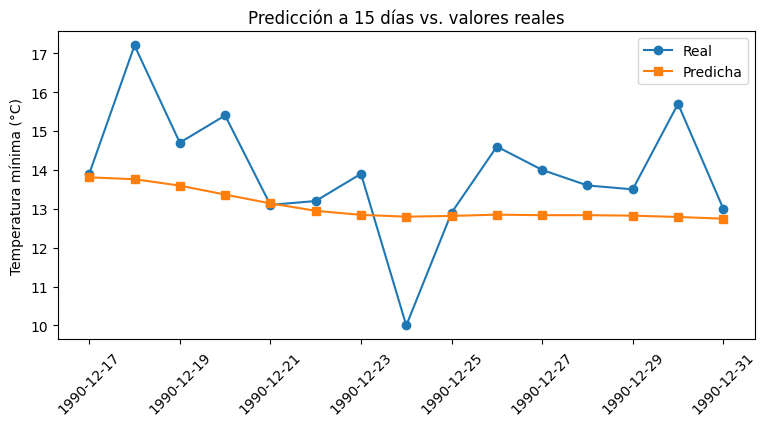

In [21]:
plt.figure(figsize=(9, 4))
plt.plot(fechas_bt, real_bt, marker="o", label="Real")
plt.plot(fechas_bt, pred_bt, marker="s", label="Predicha")
plt.xticks(rotation=45)
plt.ylabel("Temperatura mínima (°C)")
plt.title("Predicción a 15 días vs. valores reales")
plt.legend()
plt.savefig("prediccion_15dias_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

**Futuro real: los 15 días siguientes al último dato del dataset**

In [22]:
seed_fut = serie_esc[-N_INPUT:]
pred_fut = scaler.inverse_transform(predecir_n_dias(modelo, seed_fut, N_DIAS, N_INPUT))
fechas_fut = pd.date_range(df["Date"].iloc[-1] + pd.Timedelta(days=1), periods=N_DIAS)

In [23]:
tabla = pd.DataFrame({"Fecha": fechas_fut.date,
                      "Temp. predicha (°C)": pred_fut.ravel().round(2)})
print(tabla.to_string(index=False))

     Fecha  Temp. predicha (°C)
1991-01-01                13.02
1991-01-02                13.11
1991-01-03                13.13
1991-01-04                13.11
1991-01-05                13.10
1991-01-06                13.09
1991-01-07                13.06
1991-01-08                13.07
1991-01-09                13.06
1991-01-10                13.01
1991-01-11                12.96
1991-01-12                12.91
1991-01-13                12.86
1991-01-14                12.79
1991-01-15                12.75


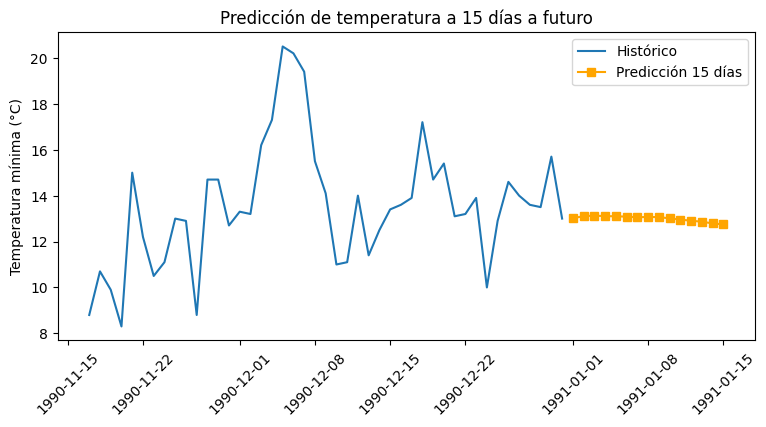

In [24]:
plt.figure(figsize=(9, 4))
plt.plot(df["Date"].iloc[-45:], valores[-45:], label="Histórico")
plt.plot(fechas_fut, pred_fut, marker="s", color="orange", label="Predicción 15 días")
plt.xticks(rotation=45)
plt.ylabel("Temperatura mínima (°C)")
plt.title("Predicción de temperatura a 15 días a futuro")
plt.legend()
plt.savefig("prediccion_15dias.png", dpi=150, bbox_inches="tight")
plt.show()